# 二维无涨落正则模

JAM 和 Basilisk 采用 $64^2$ 周期网格、$L/h_0=128$、$\Delta t^*=8$、零热噪声。比较有吸引（$a=0.0084375$）和无吸引（$a=0$）两组。斜向 $(m_x,m_y)=(2,2)$ 余弦模态的初始振幅为 $10^{-3}h_0$。连续长波色散关系为

$$s(q)=q^2\left(\frac{1}{12\mu_g}+\frac{1}{4\mu_l |q|}\right)\left(3a-\frac{\gamma q^2}{2}\right).$$

本例用 $\gamma=\mu_l=h_0=1$、$\mu_g=0.02$。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "data").is_dir():
    root = root / "postprocess"
sys.path.insert(0, str(root))
from plot_style import setup
setup()

cases = {}
for stem, expected_sign in (("normal_mode_2d", 1), ("normal_mode_2d_no_attraction", -1)):
    with np.load(root / "data" / (stem + ".npz")) as source:
        data = dict(source)
    time = data["time"]
    length = float(data["length"])
    attraction = float(data["attraction"])
    q = 2*np.pi*np.linalg.norm(data["mode"])/length
    rate = q**2*(1/.24+1/(4*q))*(3*attraction-.5*q*q)
    amplitude = [data["jam_amplitude"], data["basilisk_amplitude"]]
    fits = [np.polyfit(time, np.log(a/a[0]), 1)[0] for a in amplitude]
    assert np.sign(rate) == expected_sign and np.allclose(fits, rate, rtol=.01)
    cases[stem] = (data, rate, amplitude)
    print(f"a={attraction:g} | JAM {fits[0]:.8e} | Basilisk {fits[1]:.8e} | continuum {rate:.8e}")

unstable, stable = (entry[0] for entry in cases.values())
for key in ("initial", "time", "x", "mode", "length", "dt"):
    np.testing.assert_array_equal(unstable[key], stable[key])

a=0.0084375 | JAM 1.80082940e-03 | Basilisk 1.80082940e-03 | continuum 1.80299030e-03
a=0 | JAM -1.10158684e-03 | Basilisk -1.10158684e-03 | continuum -1.10868302e-03


## 二维厚度场与模态振幅

左图只展示有吸引时的 Basilisk 末态。右图在同一坐标框内比较有吸引和无吸引的模态振幅，黑线是连续理论，标记是两套求解器的结果。

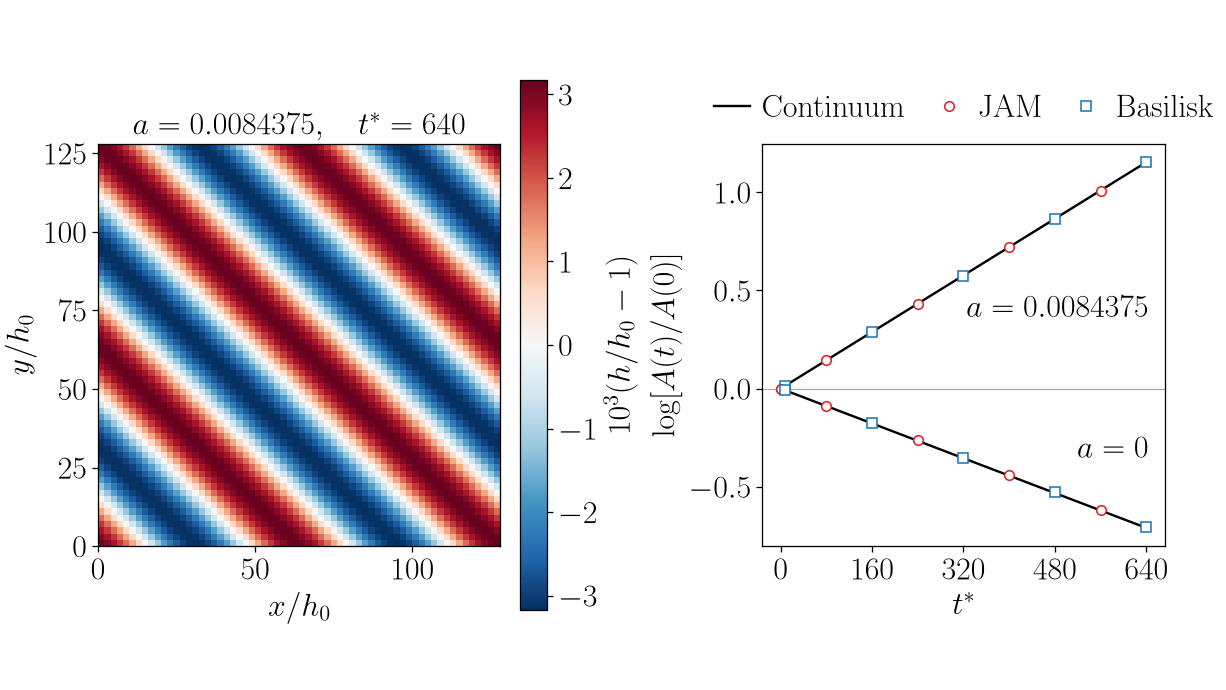

In [2]:
fig, (field_ax, rate_ax) = plt.subplots(1, 2, figsize=(32/3, 6), layout="constrained")
unstable = cases["normal_mode_2d"][0]
length = float(unstable["length"])
field = 1e3*(unstable["basilisk_final"].T - 1)
bound = np.max(abs(field))
image = field_ax.imshow(field, extent=(0, length, 0, length), origin="lower",
                        cmap="RdBu_r", vmin=-bound, vmax=bound, interpolation="nearest")
fig.colorbar(image, ax=field_ax, shrink=.78, label=r"$10^3(h/h_0-1)$")
field_ax.set(xlabel=r"$x/h_0$", ylabel=r"$y/h_0$",
             title=rf"$a={float(unstable['attraction']):g},\quad t^*={unstable['time'][-1]:g}$")

for index, (data, rate, amplitudes) in enumerate(cases.values()):
    time = data["time"]
    rate_ax.plot(time, rate*time, "k-", label="Continuum" if index == 0 else None)
    for amplitude, color, marker, start, label in zip(
            amplitudes, ("#D62728", "#1F77B4"), ("o", "s"), (0, 1), ("JAM", "Basilisk")):
        rate_ax.plot(time[start::2], np.log(amplitude/amplitude[0])[start::2],
                     marker, color=color, markerfacecolor="white",
                     label=label if index == 0 else None)
rate_ax.axhline(0., color=".65", linewidth=.7, zorder=0)
rate_ax.text(.96, .57, rf"$a={float(unstable['attraction']):g}$",
             ha="right", transform=rate_ax.transAxes)
rate_ax.text(.96, .22, r"$a=0$", ha="right", transform=rate_ax.transAxes)
rate_ax.set(xlabel=r"$t^*$", ylabel=r"$\log[A(t)/A(0)]$", xticks=(0, 160, 320, 480, 640))
rate_ax.set_box_aspect(1)
rate_ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.02), ncols=3,
               handlelength=1.15, handletextpad=.35, columnspacing=.8, borderaxespad=0.)
for ax in (field_ax, rate_ax):
    ax.grid(False, which="both")
fig.savefig(root / "figures" / "normal_mode_2d.png", dpi=600)
fig.savefig(root / "figures" / "normal_mode_2d.pdf")
plt.show()

有吸引时，JAM 和 Basilisk 拟合的增长率约为 $1.80083\times10^{-3}$。无吸引时，初始余弦扰动仅受表面张力作用，拟合率约为 $-1.10159\times10^{-3}$，连续理论给出 $-1.10868\times10^{-3}$。至 $t^*=640$，无吸引组的振幅为初值的约 49.4%。